# Array name holds a memory address (`array_reference`)

The knowledge graph around `array_reference`. This notebook draws the picture (`array_reference.png`) and writes the explanation of every relation of the concept: read it in [array_reference.md](array_reference.md).

In [1]:
# 1. Load the knowledge graph visualizer (cell 1 of scenario_explanations/kg_visualizer.ipynb) and the graph itself.
import json
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / 'data' / 'raw').exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
_visualizer = json.load(open(ROOT / 'scenario_explanations' / 'kg_visualizer.ipynb', encoding='utf-8'))
exec(''.join(_visualizer['cells'][1]['source']))
print(_loaded)


Loaded C:\Users\magnu\OneDrive\Desktop\ES_VIterbi_Personalized_Learning\data\raw\chapter1_kg_updated.json | version 3.9.8 (3.9.7 + one primary per misconception (S9c) and the … | nodes 1376 | edges 1943


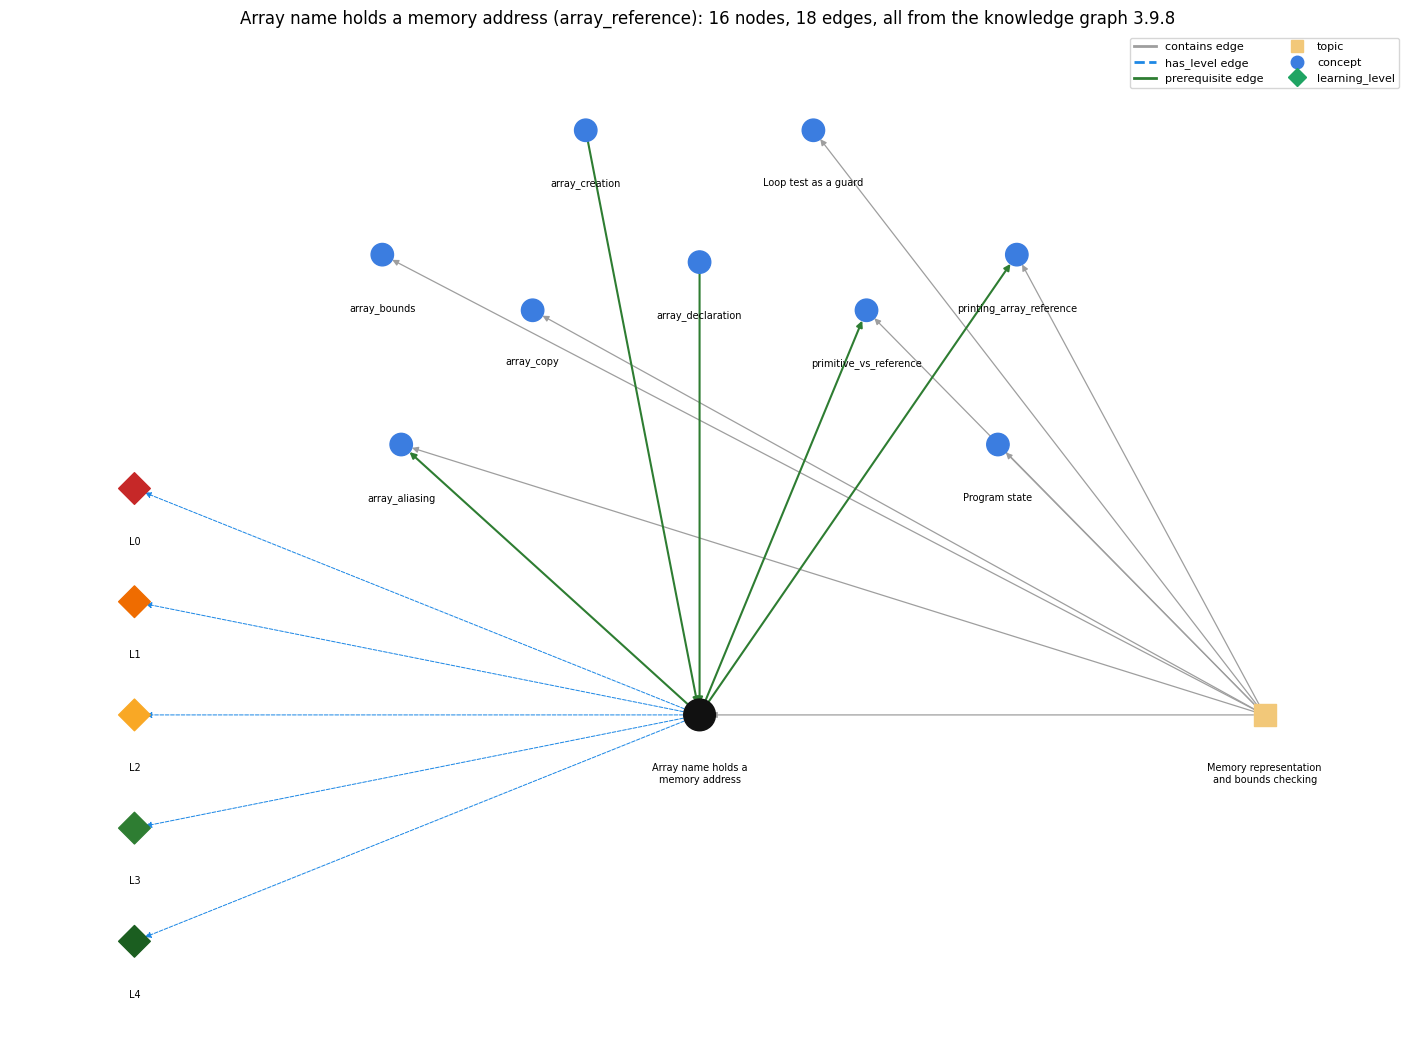

array_reference: 16 nodes, 18 edges. Written: array_reference.png, array_reference.md


In [2]:
CONCEPT = 'array_reference'

# 2. The view of the concept: the picture, and the explanation of every relation.
import re
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

HERE = Path.cwd()                      # concept_wise_graph/<concept>/
VIEW_LAYERS = {'topic', 'concept', 'learning_level', 'misconception', 'error'}
VIEW_ETYPES = {'contains', 'prerequisite', 'parallel', 'has_level', 'misconception', 'error'}
H, _ = filter_graph(VIEW_LAYERS, VIEW_ETYPES, 'All', '', 1, True, CONCEPT)   # only edges of the knowledge graph

# ---- the picture ----
pos = {n: (x, -y) for n, (x, y) in radial_layout(H, CONCEPT).items()}
S = nx.DiGraph()
S.add_nodes_from(H.nodes())
fig, ax = plt.subplots(figsize=(18, 13))
keys = []
for et in sorted({d['etype'] for _, _, d in H.edges(data=True)}):
    st = EDGE_STYLE[et]
    nx.draw_networkx_edges(S, pos, ax=ax, edgelist=[(u, v) for u, v, d in H.edges(data=True) if d['etype'] == et],
                           edge_color=st['color'], width=st['width'] * 0.6, style='dashed' if st['dashes'] else 'solid',
                           arrows=True, arrowstyle='-' if et == 'parallel' else '-|>', arrowsize=9, node_size=260)
    keys.append(Line2D([], [], color=st['color'], lw=2, ls='--' if st['dashes'] else '-', label=et + ' edge'))
MARK = {'box': 's', 'dot': 'o', 'diamond': 'D', 'triangle': '^', 'star': '*'}
for lay, st in LAYER_STYLE.items():
    ns = [n for n, d in H.nodes(data=True) if d['layer'] == lay]
    if ns:
        cols = ([LEVEL_COLOR.get(H.nodes[n]['label'], st['color']) for n in ns] if lay == 'learning_level'
                else ['#111111' if n == CONCEPT else st['color'] for n in ns])
        nx.draw_networkx_nodes(S, pos, ax=ax, nodelist=ns, node_color=cols, node_shape=MARK[st['shape']],
                               node_size=[520 if n == CONCEPT else 260 for n in ns])
        keys.append(Line2D([], [], color=st['color'], marker=MARK[st['shape']], ls='', ms=9, label=lay))
nx.draw_networkx_labels(S, {n: (x, y - 55) for n, (x, y) in pos.items()}, ax=ax, font_size=7,
                        labels={n: _wrap(d['label'], 24) for n, d in H.nodes(data=True)}, verticalalignment='top')
ax.set_title(f"{_CONCEPT[CONCEPT].get('label', CONCEPT)} ({CONCEPT}): {H.number_of_nodes()} nodes, "
             f"{H.number_of_edges()} edges, all from the knowledge graph {str(DATA.get('version'))[:5]}")
ax.legend(handles=keys, loc='upper right', fontsize=8, ncol=2)
ax.margins(0.08)
ax.axis('off')
fig.savefig(HERE / f'{CONCEPT}.png', dpi=110, bbox_inches='tight')
plt.show()

# ---- the explanation (<concept>.md): the two tables of the concept view ----
#   1. Concepts associated with the concept: concept, description, how it is associated
#   2. Every edge in this view and its full label: from, edge, to, full edge label (the exact edge logic)
def md(t):
    """Text from the graph, safe inside a markdown table cell."""
    t = str(t or '').replace('&', '&amp;').replace('<', '&lt;').replace('>', '&gt;')
    return re.sub(r'([*_`|])', r'\\\1', t).strip().replace('\n', '<br>')

def full_label(u, v, et):
    """The full label of an edge, word for word from the graph, one part per line."""
    if et in ('prerequisite', 'parallel'):
        e = _REL_EDGE.get(frozenset((u, v)), {})
        lines = [md(e.get('logic') or e.get('edge_logic'))]
        if e.get('grounding'):
            lines.append('grounding: ' + md(e['grounding']))
        for x, y in ((u, v), (v, u)):
            if (x, y) in _R_RULE:
                lines.append(f"composition rule (R) of {md(x)} with {md(y)}: {md(_R_RULE[(x, y)])}")
        return lines
    if et in ('misconception', 'error'):
        e = _MIS_EDGE.get((u, v), {})
        return (['**wrong rule:** ' + md(e.get('logic')), '**right rule:** ' + md(e.get('twin_logic'))]
                + (['role: ' + md(e['role'])] if e.get('role') else []))
    if et == 'has_level':
        e = _HAS_LEVEL.get((u, str(v).split('@')[-1]), {})
        lines = [md(e.get('logic'))]
        for i, w in enumerate(e.get('ways', [])):
            link = w.get('linked_misconception') or []
            lines.append(f"**[{i}] {md(w.get('way'))}** ({md(w.get('rule_type'))})"
                         + (' &rarr; ' + md(', '.join(link)) if link else '') + ': ' + md(w.get('exact_rule')))
        return lines
    if et == 'contains':
        return [f"topic {md(u)} contains {md(v)}"]
    return ['']

d0 = _CONCEPT[CONCEPT]
assoc = {o: w for o, w in concept_associations(CONCEPT, 1).items() if o in H}
ORDER = ['prerequisite', 'parallel', 'misconception', 'error', 'has_level', 'contains', 'precedes', 'section_prerequisite']
every = sorted(((u, v, d['etype']) for u, v, d in H.edges(data=True)),
               key=lambda x: (ORDER.index(x[2]) if x[2] in ORDER else 99, x[0], str(x[1])))

out = [f"# {d0.get('label', CONCEPT)} (`{CONCEPT}`)", '',
       md(d0.get('description', '')), '',
       f"Section {md(d0.get('section', ''))} {md(d0.get('section_title', ''))}, "
       f"topic {md(d0.get('topic', ''))} {md(d0.get('topic_title', ''))}. "
       f"From the knowledge graph {str(DATA.get('version'))[:5]} (`data/raw/chapter1_kg_updated.json`).", '',
       f"![The knowledge graph around {CONCEPT}]({CONCEPT}.png)", '',
       f"## Concepts associated with {md(CONCEPT)} ({len(assoc)})", '']
if assoc:
    out += ['| Concept | Description | How it is associated |', '| --- | --- | --- |']
    out += [f"| **{md(o)}** | {md(_CONCEPT[o].get('description', ''))} | {'<br>'.join(md(x) for x in w)} |"
            for o, w in sorted(assoc.items())]
else:
    out.append('No other concept is associated with this one in the graph.')
out += ['', f"## Every edge in this view and its full label ({len(every)})", '',
        '| From | Edge | To | Full edge label |', '| --- | --- | --- | --- |']
out += [f"| **{md(u)}** | {md(et)} | **{md(v)}** | {'<br>'.join(x for x in full_label(u, v, et) if x)} |"
        for u, v, et in every]
out.append('')
(HERE / f'{CONCEPT}.md').write_text('\n'.join(out), encoding='utf-8')
print(f"{CONCEPT}: {H.number_of_nodes()} nodes, {H.number_of_edges()} edges. Written: {CONCEPT}.png, {CONCEPT}.md")
